# 第13章 MuJoCo（1）：InvertedPendulum と Hopper を SAC で動かす

**MuJoCo** は、関節でつながった体の動きを計算する物理シミュレーターです。Gymnasium には、MuJoCo で作った連続制御の環境がいくつも入っていて、強化学習の手法を比べるときによく使われます。この章は任意の章で、MuJoCo の環境を2冊の Notebook で扱います。

- この Notebook（1冊目）: 短く学習できる **InvertedPendulum**（台車の上の棒を立て続ける）で MuJoCo の環境に慣れたあと、一本足のロボットを前へ跳ねさせる **Hopper** を、第10章の **SAC** で学習させます。報酬が「前へ進んだ分」と「倒れずにいた分」の足し算でできていることを、Gymnasium のソースで読みます
- [2冊目](ch13_2_walker2d.ipynb): 二本足のロボットの **Walker2d** を SAC で学習させます

- **前提**: [第10章 Pendulum](../ch10_pendulum/ch10_pendulum.ipynb)を終えていること（SAC の仕組みは第10章で読みました）。[第12章 BipedalWalker](../ch12_bipedalwalker/ch12_bipedalwalker.ipynb)の PPO と `VecNormalize` も、6-3節で比べるときに出てきます
- **準備**: MuJoCo の環境を動かすには、[環境構築マニュアル](../../setup/windows_setup.md)の9節「MuJoCo を入れる（任意）」の手順で、`mujoco` を入れておく必要があります
- **所要の目安**: 実行は CPU で 3 時間 15 分ほど（著者の環境で、Notebook 全体を上から実行して約 196 分。そのうち、5節の Hopper の学習が約 188 分です）
- **使う装置**: CPU で十分です（この章では GPU を使いません）

> **注記**
> - **出力の出どころ**: この Notebook に残っている出力は、著者の環境（Windows 11、CPU のみ、Gymnasium 1.3.0、MuJoCo 3.17.0、Stable-Baselines3 2.9.0、PyTorch 2.14.1）で 2026-10-30 に実行したものです。各セルの出力がそのまま期待する結果で、直後の「期待する結果」の段落に読み方を書いています。学習にかかる時間は、パソコンによって変わります。
> - **進め方**: セルを上から順に実行します。サンプルのプログラムは、読んで書き写す必要はありません。動かして、読んで、数字を変えて遊んでください。5節の学習はとても長いので、時間のあるときに始めてください。

## 0. 学習目標と完了条件

この Notebook を終えると、次のことができるようになります。

1. この章の MuJoCo の環境（InvertedPendulum・Hopper）の観測が、シミュレーターの中の関節の位置（`qpos`）と速さ（`qvel`）からできていることを説明できる
2. SB3 の SAC で InvertedPendulum と Hopper を学習させ、成績と跳ねる様子を見られる
3. Hopper の報酬の3つの項と、エピソードが終わる条件を、Gymnasium のソースの該当する行で示せる
4. 報酬の項ごとの合計から、「前へ跳ねる」動きと「倒れずに立っている」動きを見分けられる

完了条件は、この Notebook を上から最後まで実行して、5節の Hopper の SAC の **最後の時点のモデル** が、Hopper-v5 の 100 回の評価で、次の2つを両方満たすことです。

- 報酬の合計の平均が **3000 以上**
- 倒れずに 1,000 ステップ続いた回数が **90 回以上**

Gymnasium 1.3.0 に登録された Hopper-v5 の「解けた」の目安（`reward_threshold`）は 3800 です。この章の設定（学習の seed 0）では 3800 に届かなかったので、完了条件は、著者が測った値をもとに上のように決めました（5-2節）。

## 1. 全体像

この Notebook の流れは次のとおりです。

| 節 | すること | 見るもの |
|---|---|---|
| 3節 | MuJoCo に慣れる：InvertedPendulum | 観測とシミュレーターの中身、SAC の短い学習 |
| 4節 | Hopper を知る：観測・行動・報酬 | でたらめな行動、何もしない場合の成績 |
| 5節 | 動かして楽しむ：SB3 の SAC | 成績、跳ねる様子 |
| 6節 | 読む：報酬の3つの項と、終わる条件 | Gymnasium のソース、報酬の項ごとの合計、PPO で試した結果 |
| 7節 | 学習の経過を見る | 学習中の評価 |
| 8節 | 物理を変えて試す | 重力や胴体の重さを変えたときの成績 |
| 9節 | 遊んでみる | 試してみる設定 |

SAC は、概要資料の[強化学習の手法の地図](../../overview/rl.md)で「ニューラルネットワークで近似する」領域の、**方策オフ** の Actor-Critic の手法です。この章で新しく出てくる MuJoCo は、手法ではなく、環境の中で体の動きを計算する道具です。

### コードのセルの標識

コードのセルの直前の段落の始めに、そのセルの扱いを、次の4つの標識で示しています。一つずつ確かめながら読みたいときの目安にしてください。

| 標識 | 意味 |
|---|---|
| **【本質・ここで完結】** | 強化学習の中心のコードです。説明は、直前の段落と、出力のあとの段落で全部です。あとの節で中身のコードを読み直すことはありません（結果を引き合いに出すことはあります） |
| **【本質・○節で振り返る】** | 強化学習の中心のコードですが、ここでは動かして結果を見るだけで大丈夫です。中身は、示した節で読みます |
| **【道具】** | ライブラリの読み込みや、評価の関数を用意するコードなど、学習を支えるコードです。使い方が分かれば十分で、中身のコードはこの先でも説明しません |
| **【可視化】** | 絵やグラフを作るコードです。優先度は低めで、中身は読み飛ばして、出力と、そのあとの読み方だけ見れば十分です |

5-3節の跳ねる様子は、この Notebook の学習目標2に当たりますが、描くコードの中身は読み飛ばして構いません。読み方は、出力のあとの段落に書いています。

## 2. 準備

> **【道具】** ライブラリの読み込みと、評価に使う関数 `evaluate`・`sb3_policy` の用意です。

`evaluate` と `sb3_policy` は、このあとの節で何度も使います。

In [1]:
import time
from pathlib import Path

import gymnasium as gym
import imageio
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Image
from stable_baselines3 import SAC
from stable_baselines3.common.callbacks import EvalCallback
from stable_baselines3.common.env_util import make_vec_env

FIGURES = Path("figures")
FIGURES.mkdir(exist_ok=True)


# make_env() で作った環境で、方策 policy（観測 → 行動を返す関数）で episodes 回遊ばせる
# 報酬の合計の平均と標準偏差、エピソードの終わり方の回数、最後の時点の胴体の x 座標の平均を返す
def evaluate(policy, make_env, episodes=100, seed=100):
    env = make_env()
    totals = np.zeros(episodes)
    distances = np.zeros(episodes)
    endings = {"倒れた": 0, "続いた": 0}
    for i in range(episodes):
        observation, info = env.reset(seed=seed + i)
        while True:
            observation, reward, terminated, truncated, info = env.step(policy(observation))
            totals[i] += reward
            if terminated or truncated:
                break
        distances[i] = info.get("x_position", 0.0)
        endings["倒れた" if terminated else "続いた"] += 1
    return totals.mean(), totals.std(), endings, distances.mean()


# SB3 のモデルで、決まった行動を選ぶ方策を返す
def sb3_policy(model):
    return lambda observation: model.predict(observation, deterministic=True)[0]

関数の説明:

- `evaluate` は、第12章の関数の、引数の順と、終わり方の数え方と、返す値を変えたものです。100 回それぞれの `reset` に `seed=100`〜`199` を渡して遊ばせます。この章の MuJoCo の環境は、倒れたとき（InvertedPendulum は棒の角度が 0.2 ラジアンを超えたとき〈3-1節〉、Hopper は 4-1節の「健康」でなくなったとき）に `terminated` で終わり、倒れずに 1,000 ステップに届くと `truncated` で打ち切られます。前者を「倒れた」、後者を「続いた」と数えます。最後の時点の胴体の x 座標（`info["x_position"]`。始めはほぼ 0）も返すので、どれだけ前へ進んだかが分かります（InvertedPendulum の `info` には無いので 0 になります）
- `sb3_policy` は、第11章と同じ関数です

> **【可視化】** 優先度は低めです。エピソードの絵を集める関数を用意するコードです（このセルに出力は無く、使うのは5-3節です）。

`record_episode` は、第12章の関数に、環境の ID と絵の大きさ（320 × 320）の指定を足したものです。`every` ステップごとの絵（Gymnasium と MuJoCo の描画）を集めます。

In [2]:
# 方策 policy で1エピソード遊ばせ、every ステップごとの (ステップ数, 絵) の一覧を返す
# （絵は Gymnasium と MuJoCo の描画）
def record_episode(policy, env_id, seed, every):
    env = gym.make(env_id, render_mode="rgb_array", width=320, height=320)
    observation, info = env.reset(seed=seed)
    shots = [(0, env.render())]
    steps = 0
    while True:
        observation, reward, terminated, truncated, info = env.step(policy(observation))
        steps += 1
        if steps % every == 0 or terminated or truncated:
            shots.append((steps, env.render()))
        if terminated or truncated:
            return shots

## 3. MuJoCo に慣れる：InvertedPendulum

### 3-1. 観測と、シミュレーターの中身

> **【本質・ここで完結】** 説明は、ここと出力のあとの段落で全部です。

**InvertedPendulum-v5** は、レールの上を左右に動く台車に、棒が1本立っている環境です。台車を押して、棒を倒さずに立て続けます。第7・8章の CartPole と似ていますが、行動は「左右に押す力」の連続の値です。

MuJoCo の環境では、Gymnasium の環境の中に、MuJoCo のモデル（`model`。体の形・重さ・関節など、変わらないもの）とデータ（`data`。関節の位置と速さなど、時間とともに変わるもの）があり、`env.unwrapped` から見られます。

In [3]:
env = gym.make("InvertedPendulum-v5")
observation, info = env.reset(seed=0)
data = env.unwrapped.data
model = env.unwrapped.model
print("観測の空間:", env.observation_space.shape, "行動の空間:", env.action_space)
print("最初の観測:      ", np.round(observation, 4))
print("data.qpos（位置）:", np.round(data.qpos, 4))
print("data.qvel（速さ）:", np.round(data.qvel, 4))
print("関節の名前:", [model.joint(i).name for i in range(model.njnt)])
print("シミュレーターの1回の計算の時間（model.opt.timestep）:", model.opt.timestep, "秒")
print("1ステップで計算を繰り返す回数（frame_skip）:", env.unwrapped.frame_skip,
      "→ 1ステップは", env.unwrapped.dt, "秒")
print("打ち切りのステップ数:", env.spec.max_episode_steps,
      "、「解けた」の目安:", env.spec.reward_threshold)

観測の空間: (4,) 行動の空間: Box(-3.0, 3.0, (1,), float32)
最初の観測:       [ 0.0027 -0.0046 -0.0092 -0.0097]
data.qpos（位置）: [ 0.0027 -0.0046]
data.qvel（速さ）: [-0.0092 -0.0097]
関節の名前: ['slider', 'hinge']
シミュレーターの1回の計算の時間（model.opt.timestep）: 0.02 秒
1ステップで計算を繰り返す回数（frame_skip）: 2 → 1ステップは 0.04 秒
打ち切りのステップ数: 1000 、「解けた」の目安: 950.0


**期待する結果**（上の出力の読み方）: 観測は 4 つの値、行動は -3〜3 の小数1つの `Box`（形は `(1,)`）です。最初の観測の4つの値は、`data.qpos`（2つ）と `data.qvel`（2つ）をつなげたものと同じです。関節は、台車がレールの上を動く `slider` と、棒の付け根の `hinge` の2つです。シミュレーターの1回の計算は 0.02 秒で、1ステップでそれを 2 回繰り返すので、1ステップは 0.04 秒です。打ち切りは 1,000 ステップ、「解けた」の目安は 950.0 です。

観測の4つの値は、台車の位置、棒の角度、台車の速さ、棒の角速度です（Gymnasium 1.3.0 の `gymnasium/envs/mujoco/inverted_pendulum_v5.py` の環境の説明）。`_get_obs` の処理は、`data.qpos` と `data.qvel` をつなげて返すだけです。

- 報酬: 棒の角度の絶対値が 0.2 ラジアン（約 11 度）以下のあいだ、1ステップごとに 1 です
- 終わり方: 棒の角度の絶対値が 0.2 ラジアンを超えると終わります（そのステップの報酬は 0）。倒れなければ 1,000 ステップで打ち切られるので、報酬の合計は最大で 1000 です

報酬と終わり方は、`inverted_pendulum_v5.py` の `step` の処理（`terminated = bool(not np.isfinite(observation).all() or (np.abs(observation[1]) > 0.2))`、`reward = int(not terminated)`）で確かめました。

### 3-2. SAC で学習させる

> **【本質・ここで完結】** 説明は、ここと出力のあとの段落で全部です（SAC の仕組みは第10章の6節で読みました）。

第10章の SAC を、SB3 の既定値のまま 20,000 ステップ学習させます（InvertedPendulum は、RL Zoo の `sac.yml` に値がありません）。学習の前後で、でたらめな行動と比べます。

In [4]:
make_pendulum = lambda: gym.make("InvertedPendulum-v5")
pend_env = make_pendulum()
pend_env.action_space.seed(0)
mean, std, endings, _ = evaluate(
    lambda observation: pend_env.action_space.sample(), make_pendulum)
print(f"でたらめな行動: 報酬の合計の平均 {mean:.1f}、"
      f"標準偏差 {std:.1f}、{endings}")

pend_eval = EvalCallback(make_vec_env("InvertedPendulum-v5", n_envs=1, seed=1000),
                         n_eval_episodes=5, eval_freq=2_000,
                         log_path="checkpoints/sac_pendulum", verbose=0)
pend_model = SAC("MlpPolicy", make_pendulum(), seed=0, device="cpu")
start = time.perf_counter()
pend_model.learn(total_timesteps=20_000, callback=pend_eval)
print(f"学習にかかった時間: {time.perf_counter() - start:.0f} 秒")
print("2,000 ステップごとの評価（5 回の平均）:",
      np.round(np.mean(pend_eval.evaluations_results, axis=1), 1))
mean, std, endings, _ = evaluate(sb3_policy(pend_model), make_pendulum)
print(f"SAC の最後の時点のモデル: 報酬の合計の平均 {mean:.1f}、"
      f"標準偏差 {std:.1f}、{endings}")

でたらめな行動: 報酬の合計の平均 5.3、標準偏差 3.9、{'倒れた': 100, '続いた': 0}


学習にかかった時間: 233 秒
2,000 ステップごとの評価（5 回の平均）: [  95.4  120.   118.2  170.8  146.6  531.  1000.  1000.  1000.  1000. ]


SAC の最後の時点のモデル: 報酬の合計の平均 1000.0、標準偏差 0.0、{'倒れた': 0, '続いた': 100}


**期待する結果**（上の出力の読み方）: でたらめな行動は平均 5.3（標準偏差 3.9）で、100 回とも棒が倒れました。報酬は、棒の角度が 0.2 ラジアン以内のステップごとに 1 なので、棒がその範囲にあったのは平均 5 ステップほどです。学習は 233 秒でした。2,000 ステップごとの評価（5 回の平均）は、10,000 ステップまでは 95.4〜170.8 で、12,000 ステップで 531.0、14,000 ステップからは 1000.0（5 回とも 1,000 ステップ倒れずに続いた値）になりました。SAC の最後の時点のモデルは、100 回とも倒れずに続き、平均は最大の 1000.0（標準偏差 0.0）です。

`EvalCallback` は、`log_path` を渡したときだけ、評価の結果を `evaluations_results` に残します（SB3 2.9.0 の `stable_baselines3/common/callbacks.py`）。このセルでは、結果を表示するために `log_path` を渡しています。

## 4. Hopper を知る：観測・行動・報酬

### 4-1. 観測・行動・報酬・終わり方

> **【本質・ここで完結】** 説明は、ここと出力のあとの段落で全部です。

**Hopper-v5** は、胴体・もも・すね・足の4つの部分が縦につながった、一本足のロボットです。画面の奥行きの向きには動かず、前後と上下の面の中だけで動きます。3つの関節（もも・すね・足のつけ根）のモーターを動かして、前（右）へ跳ねさせます。

In [5]:
make_hopper = lambda: gym.make("Hopper-v5")
env = make_hopper()
observation, info = env.reset(seed=0)
model = env.unwrapped.model
print("観測の空間:", env.observation_space.shape, "行動の空間:", env.action_space)
print("data.qpos の数:", env.unwrapped.data.qpos.size,
      "、data.qvel の数:", env.unwrapped.data.qvel.size)
print("関節の名前:", [model.joint(i).name for i in range(model.njnt)])
print("最初の観測:", np.round(observation, 3))
print("1ステップは", env.unwrapped.dt,
      "秒、打ち切りのステップ数:", env.spec.max_episode_steps,
      "、「解けた」の目安:", env.spec.reward_threshold)

観測の空間: (11,) 行動の空間: Box(-1.0, 1.0, (3,), float32)
data.qpos の数: 6 、data.qvel の数: 6
関節の名前: ['rootx', 'rootz', 'rooty', 'thigh_joint', 'leg_joint', 'foot_joint']
最初の観測: [ 1.248e+00 -5.000e-03 -5.000e-03  3.000e-03  4.000e-03  1.000e-03
  2.000e-03  0.000e+00  4.000e-03  3.000e-03 -5.000e-03]
1ステップは 0.008 秒、打ち切りのステップ数: 1000 、「解けた」の目安: 3800.0


**期待する結果**（上の出力の読み方）: 観測は 11 個の値、行動は -1〜1 の3つの値の組（`Box(-1.0, 1.0, (3,), float32)`）です。`data.qpos` と `data.qvel` は6個ずつで、関節は、胴体の前後の位置・高さ・傾き（`rootx`・`rootz`・`rooty`）と、もも・すね・足のつけ根（`thigh_joint`・`leg_joint`・`foot_joint`）の6つです。最初の観測の最初の値（胴体の高さ）は 1.248 で、ほかの値は 0 に近い小さな値です。1ステップは 0.008 秒、打ち切りは 1,000 ステップ、「解けた」の目安は 3800.0 です。

観測の 11 個の値は、次のとおりです（`gymnasium/envs/mujoco/hopper_v5.py` の環境の説明と `_get_obs` の処理）。

| 番号 | 値 |
|---|---|
| 0〜1 | 胴体の高さ（z 座標）、胴体の傾きの角度 |
| 2〜4 | もも・すね・足のつけ根の関節の角度 |
| 5〜10 | 胴体の前後の速さ、上下の速さ、傾きの角速度、3つの関節の角速度（-10〜10 に切り詰めた値） |

- `data.qpos` の6個のうち、最初の1個（胴体の前後の位置 `rootx`）は、観測から外されています（`exclude_current_positions_from_observation=True` が既定値）。位置は `info["x_position"]` で分かります
- 行動（3つの値、どれも -1〜1）: もも・すね・足のつけ根の関節のモーターの力です

報酬は、次の3つの項の足し算です（`hopper_v5.py` の `_get_rew`。6節で読みます）。

| 項 | 1ステップの値 | `info` のキー |
|---|---|---|
| 前へ進んだ分 | 胴体の前後の速さ（1ステップで進んだ距離 ÷ 0.008 秒） | `reward_forward` |
| 倒れずにいた分 | 「健康」なら 1 | `reward_survive` |
| モーターの力の分 | −0.001 × 行動の値の2乗の和 | `reward_ctrl` |

「健康」は、胴体の高さが 0.7 より大きく、胴体の傾きの角度が −0.2〜0.2 ラジアンの間にあり、関節の角度と、切り詰める前の速さ（`data.qpos` と `data.qvel` から、胴体の前後の位置と高さを除いた値）がどれも −100〜100 の間にあることです（`is_healthy`）。健康でなくなると、そこでエピソードが終わります。終わらなければ 1,000 ステップで打ち切られます。

### 4-2. でたらめな行動と、何もしない場合

> **【本質・ここで完結】** 説明は、ここと出力のあとの段落で全部です。

でたらめな行動と、何もしない行動（3つの値を 0 にする）で、それぞれ 100 回遊ばせます。

In [6]:
env = make_hopper()
env.action_space.seed(0)
for name, policy in [
        ("でたらめな行動", lambda observation: env.action_space.sample()),
        ("何もしない", lambda observation: np.zeros(3, dtype=np.float32))]:
    mean, std, endings, distance = evaluate(policy, make_hopper)
    print(f"{name}: 報酬の合計の平均 {mean:.1f}、標準偏差 {std:.1f}、{endings}、"
          f"最後の x 座標の平均 {distance:.2f} m")

でたらめな行動: 報酬の合計の平均 17.7、標準偏差 18.9、{'倒れた': 100, '続いた': 0}、最後の x 座標の平均 -0.03 m


何もしない: 報酬の合計の平均 154.3、標準偏差 53.9、{'倒れた': 100, '続いた': 0}、最後の x 座標の平均 0.00 m


**期待する結果**（上の出力の読み方）: でたらめな行動は平均 17.7（標準偏差 18.9）、何もしない場合は平均 154.3（標準偏差 53.9）で、どちらも 100 回とも倒れました。最後の x 座標の平均は -0.03 m と 0.00 m で、前へは進んでいません。

## 5. 動かして楽しむ：SB3 の SAC

### 5-1. 学習させる

> **【本質・ここで完結】** 説明は、ここと出力のあとの段落で全部です（SAC の仕組みは第10章の6節で読みました）。

ハイパーパラメータは、**RL Zoo** の MuJoCo の環境用の SAC の値です（出典は末尾）。RL Zoo の `sac.yml` の項目は旧版の `Hopper-v4` 用で、この章ではその値を Hopper-v5 に使います。Hopper の値は、MuJoCo の環境に共通の設定で、学習のステップ数と `learning_starts` 以外は SB3 の既定値です。

| 設定 | 値 | 第10章（Pendulum） | 意味 |
|---|---|---|---|
| `n_timesteps` | 1,000,000（RL Zoo） | 20,000 | 学習のステップ数 |
| `learning_starts` | 10,000（RL Zoo） | （既定値 100） | 学習を始める前に、でたらめな行動で集めるステップ数 |
| `learning_rate` | 0.0003（既定値） | 0.001 | 学習率 |
| `buffer_size` | 1,000,000（既定値） | （既定値） | リプレイバッファに入れておく経験の数 |
| `batch_size` | 256（既定値） | （既定値） | 重みを1回動かすのに使う経験の数 |
| `gamma`・`tau` | 0.99・0.005（既定値） | （既定値） | 割引率、ターゲットのネットワークを近づける割合 |
| `train_freq`・`gradient_steps` | 1・1（既定値） | （既定値） | 1ステップごとに、重みを1回動かす |

ネットワークは、方策と Q 関数のどちらも 256 × 256 です（SB3 2.9.0 の `stable_baselines3/sac/sac.py` の `__init__` と `stable_baselines3/sac/policies.py`）。

学習中の様子を見るために、`EvalCallback` で、50,000 ステップごとに 5 回遊ばせて評価します。著者の環境では 11,278 秒（約 188 分）かかりました。学習が終わったら、モデルを `checkpoints` フォルダに保存します（保存したモデルの使い方は、[2冊目](ch13_2_walker2d.ipynb)の5節で読みます）。

In [7]:
seed = 0
train_env = make_vec_env("Hopper-v5", n_envs=1, seed=seed)
eval_env = make_vec_env("Hopper-v5", n_envs=1, seed=1000 + seed)
callback = EvalCallback(eval_env, n_eval_episodes=5, eval_freq=50_000,
                        log_path="checkpoints/sac_hopper", verbose=0)
model = SAC("MlpPolicy", train_env, learning_starts=10_000,
            seed=seed, device="cpu", tensorboard_log="logs")
start = time.perf_counter()
model.learn(total_timesteps=1_000_000, callback=callback, tb_log_name="sac_hopper")
print(f"学習にかかった時間: {time.perf_counter() - start:.0f} 秒")
model.save("checkpoints/sac_hopper_final")
print("50,000 ステップごとの評価（5 回の平均）:",
      np.round(np.mean(callback.evaluations_results, axis=1), 1))

学習にかかった時間: 11278 秒


50,000 ステップごとの評価（5 回の平均）: [1008.8  465.8  522.4  785.8  887.9 1798.9 3308.3 3408.6 3426.9 3460.
 3468.8 3458.2 3494.7 3494.5 3517.4 3519.6 3516.8 3537.9 3526.1 3532.2]


**期待する結果**（上の出力の読み方）: 学習には 11,278 秒（約 188 分）かかりました。50,000 ステップごとの評価（5 回の平均）は、1 回目の 1008.8 のあと、100,000 ステップで 465.8 に下がり、そこから上がって、350,000 ステップで 3308.3 になりました。400,000 ステップからは 3408.6〜3537.9 の間で、ゆるやかに上がっています。

`seed=0`（学習）と `seed=1000`（学習中の評価の環境）を固定しています。`checkpoints` フォルダと `logs` フォルダは、学習のたびに作り直せるものなので、Git の管理から外しています。学習の記録を TensorBoard で見る手順は、[第1章](../ch01_first_training/ch01_first_training.ipynb)の6-2節と同じです（フォルダを `chapters\ch13_mujoco\logs` にします）。

### 5-2. 成績を測る

> **【本質・ここで完結】** 説明は、ここと出力のあとの段落で全部です。

最後の時点のモデルを、100 回評価します。

In [8]:
mean, std, endings, distance = evaluate(sb3_policy(model), make_hopper)
print(f"最後の時点のモデル: 報酬の合計の平均 {mean:.1f}、標準偏差 {std:.1f}、{endings}、"
      f"最後の x 座標の平均 {distance:.2f} m")

最後の時点のモデル: 報酬の合計の平均 3531.7、標準偏差 4.2、{'倒れた': 0, '続いた': 100}、最後の x 座標の平均 20.26 m


**期待する結果**（上の出力の読み方）: 最後の時点のモデルは、100 回の平均が 3531.7（標準偏差 4.2）で、100 回とも倒れずに 1,000 ステップ続きました。最後の x 座標の平均は 20.26 m です。完了条件（平均 3000 以上、続いた回数 90 回以上）を両方満たしています。「解けた」の目安の 3800 には届いていません。

この節の値は、著者が別に動かした試作のスクリプト（同じ設定と seed）で測った値と同じでした。この章では、学習の seed を 0 だけで測りました。学習には長い時間がかかるので、seed を変えた成績は測っていません。seed を変えると、成績が変わる場合があります（第7章・第11章では、seed によって成績が変わりました）。

### 5-3. 跳ねる様子を見る

> **【可視化】** 優先度は低めです。絵を集めて GIF に保存するコードです。

最後の時点のモデルで1エピソード遊ばせ、10 ステップごとの絵を GIF に保存します。Hopper の1ステップは 0.008 秒（1 秒に 125 ステップ。`render_fps`）なので、1 枚を 80 ミリ秒で表示すると、ほぼその速さです。画面は、胴体に合わせて動きます。

エピソードのステップ数: 1000


GIF の枚数: 101


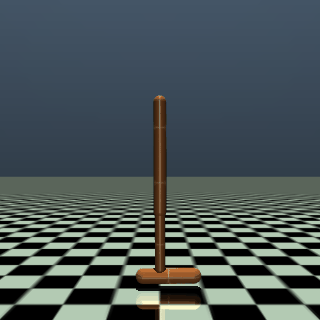

In [9]:
shots = record_episode(sb3_policy(model), "Hopper-v5", seed=0, every=10)
print("エピソードのステップ数:", shots[-1][0])
imageio.v3.imwrite(FIGURES / "ch13_sac_hopper.gif", [frame for _, frame in shots],
                   duration=80, loop=0)
print("GIF の枚数:", len(shots))
Image(filename=FIGURES / "ch13_sac_hopper.gif")

**期待する結果**（上の出力の読み方）: このエピソードは、倒れずに打ち切りの 1,000 ステップまで続きました。出力の「GIF の枚数: 101」は、最初の絵と、10 ステップごとの絵 100 枚を合わせた数です（最後の 1,000 ステップ目は 10 の倍数なので、10 ステップごとの絵に入っています）。

**期待する結果**（VS Code などで実行した場合）: 上の出力は、上のエピソードの GIF です。ロボットは、まっすぐ立った姿勢から、体を進む向き（右）へ少し傾け、膝を曲げ伸ばしして、1本の脚で跳ねながら進みます。最後の 1,000 ステップまで倒れません。

> **【可視化】** 優先度は低めです。コマ送りの図を作るコードです。

GitHub でこの Notebook を読んでいる場合、上の出力の GIF の動きは見られません（著者が、private だった 2026-10-01 に第0章で、public にした後の 2026-10-10 に第3〜5章で確かめました）。GIF は、この章のフォルダの [README.md](README.md) でも見られます。Notebook の中でも見られるように、次のセルで、同じエピソードのコマ送りの図を作ります。

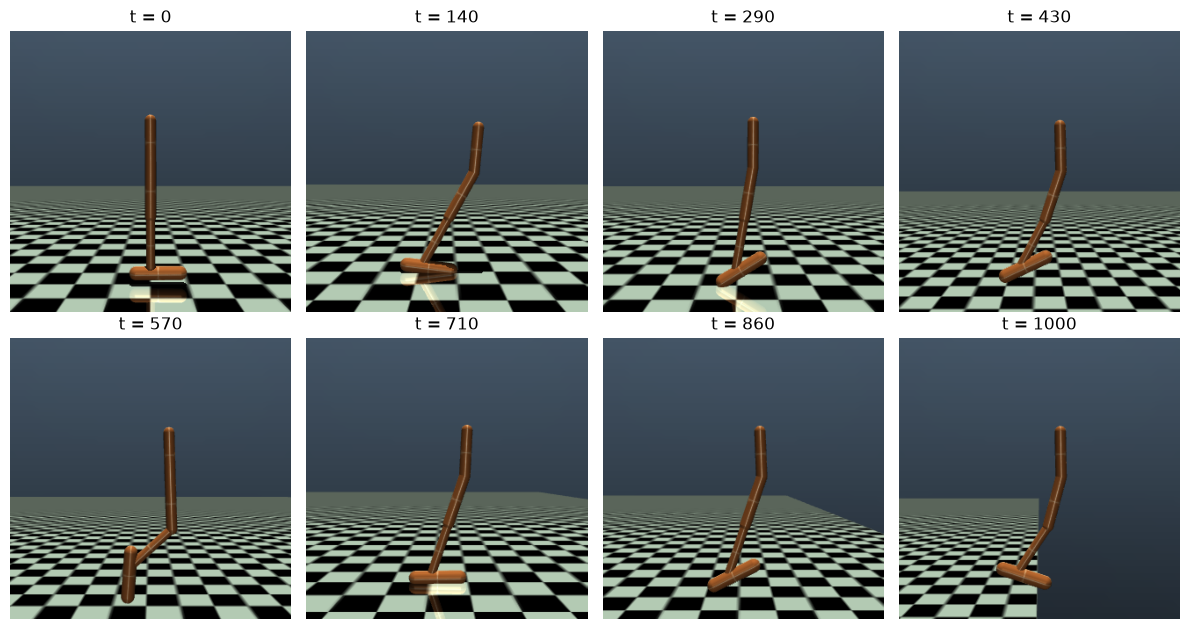

In [10]:
picks = np.linspace(0, len(shots) - 1, 8).round().astype(int)  # 等間隔に 8 枚選ぶ
fig, axes = plt.subplots(2, 4, figsize=(12, 6.4))
for ax, i in zip(axes.flat, picks):
    t, frame = shots[i]
    ax.imshow(frame)
    ax.set_title(f"t = {t}")
    ax.axis("off")
fig.tight_layout()
fig.savefig(FIGURES / "ch13_sac_hopper_frames.png", dpi=80)
plt.show()

**期待する結果**（上の出力の読み方）: 上のエピソードから、等間隔に選んだ 8 枚（t = 0、140、290、430、570、710、860、1000）です。t = 0 では、まっすぐ立っています。t = 140 から t = 1000 までは、体を右へ傾け、膝を曲げたり伸ばしたりしながら跳ねていて、どの絵でも倒れていません。t = 710 からは右奥に床の模様の端が見え、t = 860・t = 1000 では、その先が暗く描かれています。`hopper.xml` の床（`floor`）の大きさは `size="20 20 .125"` で、著者は、ロボットが床の端（MuJoCo の平面の `size` は半分の長さを表すので、端は x = 20 m）に近づき、その先が画面に入ったためと考えています（確かめてはいません。2冊目の Walker2d の床は `size="40 40 40"` で、約 29 m 進んでも、模様は切れていません）。

## 6. 読む：報酬の3つの項と、終わる条件

### 6-1. ソースを読む

Hopper の報酬は、`hopper_v5.py` の `_get_rew` で計算しています（Gymnasium 1.3.0。コメントは著者が足したもの）。

```python
# 前へ進んだ分（重みの既定値は 1）
forward_reward = self._forward_reward_weight * x_velocity
# 倒れずにいた分（健康なら 1、でなければ 0）
healthy_reward = self.healthy_reward
rewards = forward_reward + healthy_reward
# 0.001 × 行動の値の2乗の和
ctrl_cost = self.control_cost(action)
costs = ctrl_cost
reward = rewards - costs
```

`x_velocity` は、`step` の中で、`do_simulation` の前後の胴体の x 座標の差を、1ステップの時間 `self.dt`（0.008 秒）で割った値です。「健康」かどうかは、`is_healthy` で決めます。

```python
# 胴体の高さと、傾きの角度
z, angle = self.data.qpos[1:3]
# qpos と qvel をつなげたものから、x 座標と高さを除いた値
state = self.state_vector()[2:]
# 既定値は -100〜100
healthy_state = np.all(np.logical_and(min_state < state, state < max_state))
# 既定値は 0.7〜（上限なし）
healthy_z = min_z < z < max_z
# 既定値は -0.2〜0.2
healthy_angle = min_angle < angle < max_angle
is_healthy = all((healthy_state, healthy_z, healthy_angle))
```

`step` は、`terminated = (not self.is_healthy) and self._terminate_when_unhealthy` で、健康でなくなったときにエピソードを終わらせます（`terminate_when_unhealthy=True` が既定値）。

この作りから、次のことが言えます。

- 倒れずに 1,000 ステップ続けば、前へ進まなくても「倒れずにいた分」だけで合計 1000 になります
- 前へ速く進むほど「前へ進んだ分」が増えます。ただし、跳ねる途中で胴体が 0.2 ラジアンより傾いたり、低くなったりすると、そこで終わってしまいます

### 6-2. 報酬を項ごとに足してみる

> **【本質・ここで完結】** 説明は、ここと出力のあとの段落で全部です。

5節のモデルと、何もしない場合とで、10 回のエピソードの報酬を、`info` の3つのキーごとに足して比べます。

In [11]:
# 方策 policy で episodes 回遊ばせ、報酬の3つの項ごとの合計（1エピソードあたりの平均）を返す
def reward_terms(policy, make_env, episodes=10, seed=100):
    sums = {"reward_forward": 0.0, "reward_survive": 0.0, "reward_ctrl": 0.0}
    env = make_env()
    for i in range(episodes):
        observation, info = env.reset(seed=seed + i)
        while True:
            observation, reward, terminated, truncated, info = env.step(policy(observation))
            for key in sums:
                sums[key] += info[key]
            if terminated or truncated:
                break
    return {key: round(float(value) / episodes, 1) for key, value in sums.items()}


print("SAC（5節のモデル）:", reward_terms(sb3_policy(model), make_hopper))
print("何もしない:        ",
      reward_terms(lambda observation: np.zeros(3, dtype=np.float32), make_hopper))

SAC（5節のモデル）: {'reward_forward': 2533.2, 'reward_survive': 1000.0, 'reward_ctrl': -0.9}


何もしない:         {'reward_forward': -5.0, 'reward_survive': 143.8, 'reward_ctrl': 0.0}


**期待する結果**（上の出力の読み方）: 5節のモデルの1エピソードあたりの合計は、前へ進んだ分が 2533.2、倒れずにいた分が 1000.0、モーターの力の分が -0.9 で、足すと 3532.3 です（10 回の平均なので、5-2節の 100 回の平均 3531.7 とは少し違います）。報酬の約 7 割は前へ進んだ分で、倒れずにいた分は、1,000 ステップ続いたときの最大の 1000 です。何もしない場合は、前へ進んだ分が -5.0、倒れずにいた分が 143.8、モーターの力の分が 0.0 で、倒れずにいた分がほとんどです。

### 6-3. PPO で試した結果（参考）

この章の手法を決める前に、著者は、第11・12章の PPO でも Hopper を学習させました。RL Zoo v2.9.0 の PPO の `Hopper-v4` 用の調整済みの値を Hopper-v5 に使い（1,000,000 ステップ。第12章と同じ `VecNormalize` で観測と報酬を正規化する設定）、学習の seed は 0 だけです。この Notebook では動かしていません。評価は、この Notebook の `evaluate` と同じ 100 回、最後の時点のモデルです。

| 手法 | 報酬の合計の平均 | 標準偏差 | 倒れた | 続いた | 最後の x 座標の平均 | 著者の環境での学習の時間 |
|---|---|---|---|---|---|---|
| SAC（5節のモデル） | 3531.7 | 4.2 | 0 回 | 100 回 | 20.26 m | 約 188 分 |
| PPO（著者の試作） | 1023.4 | 0.5 | 0 回 | 100 回 | 0.19 m | 約 66 分 |

- PPO の最後の時点のモデルは、100 回とも倒れずに 1,000 ステップ続きましたが、前へはほとんど進んでいません。報酬の合計 1023.4 は、6-1節で見た「倒れずにいた分」だけの合計 1000 とほぼ同じです。PPO は、前へほとんど進まずに、倒れないでいる動きを覚えたと考えられます（著者は、この動きを絵では確かめていません）。4-2節のとおり、何もしなければ倒れるので、倒れずに続けること自体は学習した結果です
- PPO の学習中の評価（50,000 ステップごとに 5 回の平均）は、1000 前後の回と、56.9・32.3 などの大きく低い回が混ざり、最後の 1,000,000 ステップでは 1023.4 でした（5 回の平均）
- 学習の時間は、PPO のほうがずっと短く済みました

著者は、この結果から、この章では SAC を使うことにしました。seed 1 つずつの比較なので、PPO が Hopper に向かないとは、これだけでは言えません。RL Zoo が公開している学習済みのエージェントの成績（v2.9.0 の `benchmark.md`。それぞれ1回の学習で、環境は旧版の Hopper-v3）では、平均は PPO が 2410.4、SAC が 2325.5 です。

## 7. 学習の経過を見る

> **【可視化】** 優先度は低めです。学習中の評価を図に描くコードです。

5節の、学習中の評価（5 回の平均）を並べます。

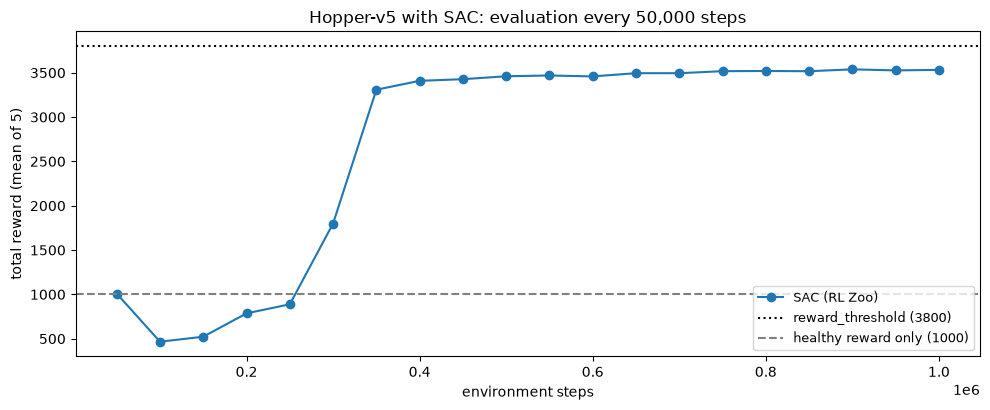

In [12]:
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.plot(callback.evaluations_timesteps,
        np.mean(callback.evaluations_results, axis=1), "o-",
        color="tab:blue", label="SAC (RL Zoo)")
ax.axhline(3800, color="black", linestyle=":", label="reward_threshold (3800)")
ax.axhline(1000, color="gray", linestyle="--", label="healthy reward only (1000)")
ax.set_xlabel("environment steps")
ax.set_ylabel("total reward (mean of 5)")
ax.set_title("Hopper-v5 with SAC: evaluation every 50,000 steps")
ax.legend(loc="lower right", fontsize=9)
fig.tight_layout()
fig.savefig(FIGURES / "ch13_hopper_learning_curve.png", dpi=80)
plt.show()

**期待する結果**（上の出力の読み方）: 青い丸は、50,000 ステップの 1008.8 から、100,000 ステップで 465.8 に下がり、300,000 ステップで 1798.9、350,000 ステップで 3308.3 と急に上がりました。そのあとは 3408.6〜3537.9 の間で、ゆるやかに上がっています。黒い点線の「解けた」の目安の 3800 には届いていません。灰色の破線は、倒れずにいた分だけで 1,000 ステップ続いたときの合計 1000 です。

## 8. 物理を変えて試す

> **【本質・ここで完結】** 説明は、ここと出力のあとの段落で全部です。

MuJoCo のモデル（`env.unwrapped.model`）の値は、環境を作ったあとで書き換えられます。5節のモデルは、重力が 9.81 m/s²、胴体の重さが元のままの Hopper で学習しました。重力を半分・1.5 倍にした場合と、胴体を 2 倍に重くした場合に、学習し直さずに、そのまま 100 回評価します。

In [13]:
# 重力を gravity 倍、胴体の重さを torso 倍にした Hopper を作る関数を返す
def make_changed_hopper(gravity=1.0, torso=1.0):
    def make_env():
        env = gym.make("Hopper-v5")
        m = env.unwrapped.model
        m.opt.gravity[2] *= gravity
        m.body_mass[m.body("torso").id] *= torso
        return env
    return make_env


print("重力:", make_hopper().unwrapped.model.opt.gravity,
      "、胴体の重さ:",
      round(float(make_hopper().unwrapped.model.body("torso").mass[0]), 2),
      "kg")
for name, kwargs in [("元のまま", {}), ("重力 0.5 倍", dict(gravity=0.5)),
                     ("重力 1.5 倍", dict(gravity=1.5)), ("胴体 2 倍", dict(torso=2.0))]:
    mean, std, endings, distance = evaluate(
        sb3_policy(model), make_changed_hopper(**kwargs))
    print(f"{name}: 報酬の合計の平均 {mean:.1f}、標準偏差 {std:.1f}、{endings}、"
          f"最後の x 座標の平均 {distance:.2f} m")

重力: [ 0.    0.   -9.81] 、胴体の重さ: 3.67 kg


元のまま: 報酬の合計の平均 3531.7、標準偏差 4.2、{'倒れた': 0, '続いた': 100}、最後の x 座標の平均 20.26 m


重力 0.5 倍: 報酬の合計の平均 429.9、標準偏差 5.6、{'倒れた': 100, '続いた': 0}、最後の x 座標の平均 1.88 m


重力 1.5 倍: 報酬の合計の平均 664.4、標準偏差 13.4、{'倒れた': 100, '続いた': 0}、最後の x 座標の平均 3.75 m


胴体 2 倍: 報酬の合計の平均 613.8、標準偏差 1.9、{'倒れた': 100, '続いた': 0}、最後の x 座標の平均 3.35 m


**期待する結果**（上の出力の読み方）: 重力は z の向きに -9.81 m/s²、胴体の重さは 3.67 kg です。元のままでは、5-2節と同じ平均 3531.7 です。重力を 0.5 倍にすると平均 429.9、1.5 倍にすると平均 664.4、胴体を 2 倍に重くすると平均 613.8 で、3 通りとも 100 回すべてで倒れました（最後の x 座標の平均は 1.88 m、3.75 m、3.35 m）。

この3通りでは、2冊目の Walker2d のモデル（重力 1.5 倍では 100 回のうち 93 回続いた）と比べて、この Hopper のモデルは、物理の変化に弱い結果でした。

`m.opt.gravity` は重力の向きと大きさ（x・y・z の順、単位は m/s²）、`m.body_mass` は体の部分ごとの重さ（kg）です。`m.body("torso")` で、名前から体の部分を探しています。書き換えは、その環境の中のモデルだけに効き、次に `gym.make` で作る環境は元のままです。

## 9. 遊んでみる

**やってみよう**:

- 3-2節の InvertedPendulum の学習の `total_timesteps=20_000` を減らして、何ステップで 1000 に届くかを見てみてください（3-2節の出力では、14,000 ステップの評価で 1000 になりました）
- 8節の `make_changed_hopper` に `gravity=0.9` や `gravity=1.1` を渡して、どのくらいの変化まで倒れずに跳べるかを見てみてください（著者は確かめていません）
- 6-2節の `reward_terms` に、でたらめな行動の方策を渡して、項ごとの合計を比べてみてください（著者は確かめていません）
- `gym.make("Hopper-v5", healthy_reward=0.5)` のように、倒れずにいた分の重み（既定は 1.0。`hopper_v5.py`）を変えた環境で学習させてみてください（学習には5節と同じくらいの時間がかかります。著者は確かめていません）

## 10. まとめ

この Notebook では、InvertedPendulum と Hopper を SAC で学習させました。

| したこと | 使ったもの | 節 |
|---|---|---|
| MuJoCo のモデルとデータを見て、InvertedPendulum を SAC で学習させる | `env.unwrapped.model`・`data`、`SAC` | 3節 |
| Hopper の観測・行動・報酬を確かめ、でたらめな行動・何もしない場合で遊ぶ | `env.observation_space`、`info` | 4節 |
| SB3 の SAC を RL Zoo の値で学習させる | `SAC`、`make_vec_env`、`EvalCallback` | 5節 |
| 報酬の3つの項と終わる条件を読み、項ごとに足して比べる | `hopper_v5.py` の `_get_rew`・`is_healthy`、`reward_terms()` | 6節 |
| 学習の経過を見る | `callback.evaluations_results` | 7節 |
| 重力と胴体の重さを変えて試す | `model.opt.gravity`、`model.body_mass` | 8節 |

- この章の MuJoCo の環境の観測は、シミュレーターの中の関節の位置（`qpos`）と速さ（`qvel`）からできています。InvertedPendulum では、観測は `qpos` と `qvel` をつなげたものそのものでした
- InvertedPendulum は、SAC を SB3 の既定値で 20,000 ステップ学習させると（著者の環境で 233 秒）、100 回とも 1,000 ステップ倒れずに続きました
- Hopper は、SAC を RL Zoo の値で 1,000,000 ステップ学習させると（著者の環境で約 188 分）、最後の時点のモデルは平均 3531.7 で、100 回とも倒れずに続き、平均 20.26 m 進みました（学習の seed 0）
- Hopper の報酬は「前へ進んだ分」＋「倒れずにいた分」−「モーターの力の分」です。5節のモデルの報酬の約 7 割は前へ進んだ分でした。著者が試した PPO は、ほとんど前へ進まずに倒れないでいるだけで、合計 1000 ほどになりました
- 学習し直さないモデルは、重力や胴体の重さを変えると、3 通りとも 100 回すべてで倒れました

- 次に読むもの: [第13章 MuJoCo（2）：Walker2d](ch13_2_walker2d.ipynb)
- 手法の位置づけを見直したいときは、概要資料の[強化学習](../../overview/rl.md)に戻ってください

## 出典

この Notebook は、次の文献・公式の文書と、導入した Gymnasium 1.3.0・MuJoCo 3.17.0・Stable-Baselines3 2.9.0 のソースと動作（2026-10-30 確認）をもとに、著者の言葉でまとめたものです。逐語の転載ではありません。6節のコードの引用は Gymnasium（MIT License）の `hopper_v5.py` の該当する行です。

- T. Haarnoja, A. Zhou, P. Abbeel, S. Levine, "Soft actor-critic: Off-policy maximum entropy deep reinforcement learning with a stochastic actor", ICML 2018（SAC）
- E. Todorov, T. Erez, Y. Tassa, "MuJoCo: A physics engine for model-based control", IROS 2012（MuJoCo）
- RL Baselines3 Zoo, v2.9.0 の `hyperparams/sac.yml`（MuJoCo の環境の SAC のハイパーパラメータ）: https://github.com/DLR-RM/rl-baselines3-zoo/blob/v2.9.0/hyperparams/sac.yml
- RL Baselines3 Zoo, v2.9.0 の `hyperparams/ppo.yml`（6-3節の PPO の Hopper のハイパーパラメータ）: https://github.com/DLR-RM/rl-baselines3-zoo/blob/v2.9.0/hyperparams/ppo.yml
- RL Baselines3 Zoo, v2.9.0 の `benchmark.md`（6-3節の学習済みのエージェントの成績）: https://github.com/DLR-RM/rl-baselines3-zoo/blob/v2.9.0/benchmark.md
- Stable-Baselines3 のソース（v2.9.0。`stable_baselines3/sac/sac.py`・`stable_baselines3/sac/policies.py`・`stable_baselines3/common/callbacks.py`）: https://github.com/DLR-RM/stable-baselines3/tree/v2.9.0/stable_baselines3
- Gymnasium 1.3.0 のソース（導入したパッケージの中の `gymnasium/envs/mujoco/inverted_pendulum_v5.py`・`hopper_v5.py` の環境の説明と `step`・`_get_obs`・`_get_rew`・`is_healthy` の処理、`gymnasium/envs/mujoco/assets/hopper.xml`）

5節の GIF とコマ送りの図の絵は、Gymnasium（MIT License）の Hopper の環境を、MuJoCo（Apache License 2.0）の描画処理で描いたものです（体の形は `hopper.xml` で決められ、画像の素材は使っていません）。グラフは、著者が matplotlib で描いたものです。この教科書のライセンスと、使っている第三者のソフトウェアの一覧は、リポジトリの [LICENSE.md](../../LICENSE.md) にあります。